In [1]:
# Breast Cancer Classification Using Machine Learning


In [2]:
# Section 1: Import required libraries

# Libraries for data analysis
import pandas as pd
import numpy as np

# Libraries for creating graphs
import matplotlib.pyplot as plt
import seaborn as sns

# Library for loading the breast cancer dataset
from sklearn.datasets import load_breast_cancer

# Libraries for splitting and preparing data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Machine learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Libraries for evaluating model performance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully")


Libraries imported successfully


In [3]:
# Section 2: Load the breast cancer dataset

# Load the Breast Cancer Wisconsin dataset
cancer = load_breast_cancer()

# Convert the dataset into a pandas DataFrame
df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Add the target column
# 0 = Malignant, 1 = Benign
df["target"] = cancer.target

# Add diagnosis names for better understanding
df["diagnosis"] = df["target"].map({
    0: "Malignant",
    1: "Benign"
})

# Display dataset information
print("Total records:", len(df))
print("Total features:", len(cancer.feature_names))

# Display first five rows
print(df.head())


Total records: 569
Total features: 30
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst perimeter  worst

In [4]:
# Section 3: Check data quality

# Check dataset size
print("Dataset shape:", df.shape)

# Check missing values
print("Missing values:", df.isnull().sum().sum())

# Check duplicate records
print("Duplicate records:", df.duplicated().sum())

# Count benign and malignant tumors
print("\nDiagnosis distribution:")
print(df["diagnosis"].value_counts())

# Display statistical information
print("\nDataset summary:")
print(df[cancer.feature_names].describe())


Dataset shape: (569, 32)
Missing values: 0
Duplicate records: 0

Diagnosis distribution:
diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64

Dataset summary:
       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.0489

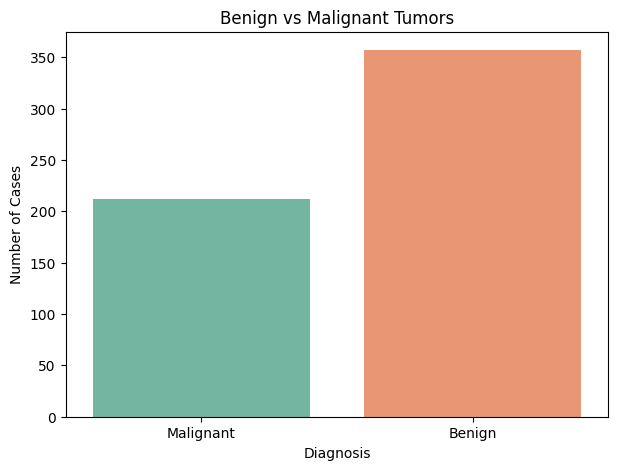

In [5]:
# Section 4.1: Visualize tumor distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="diagnosis",
    hue="diagnosis",
    palette="Set2",
    legend=False
)

plt.title("Benign vs Malignant Tumors")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Cases")
plt.show()


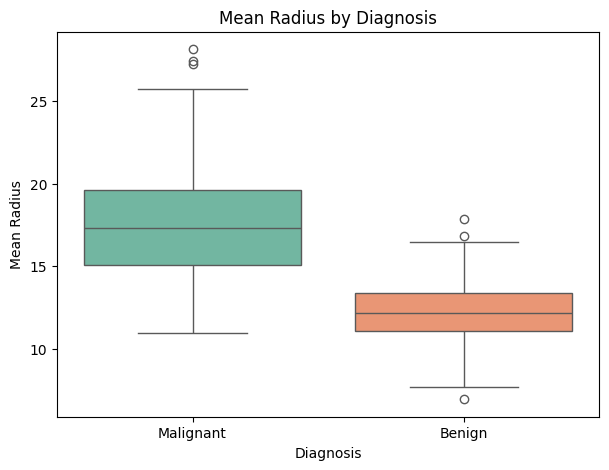

In [6]:
# Section 4.2: Compare mean radius by diagnosis

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="diagnosis",
    y="mean radius",
    hue="diagnosis",
    palette="Set2",
    legend=False
)

plt.title("Mean Radius by Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Mean Radius")
plt.show()


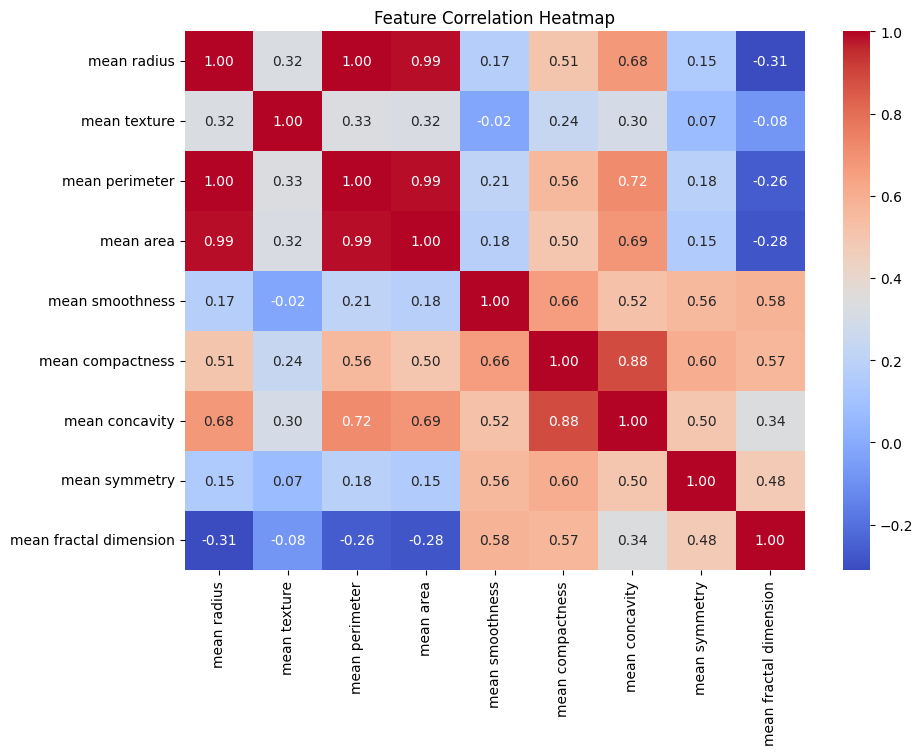

In [7]:
# Section 4.3: Check relationships between features

# Select important diagnostic features
features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness",
    "mean compactness",
    "mean concavity",
    "mean symmetry",
    "mean fractal dimension"
]

# Calculate correlations
correlation = df[features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()


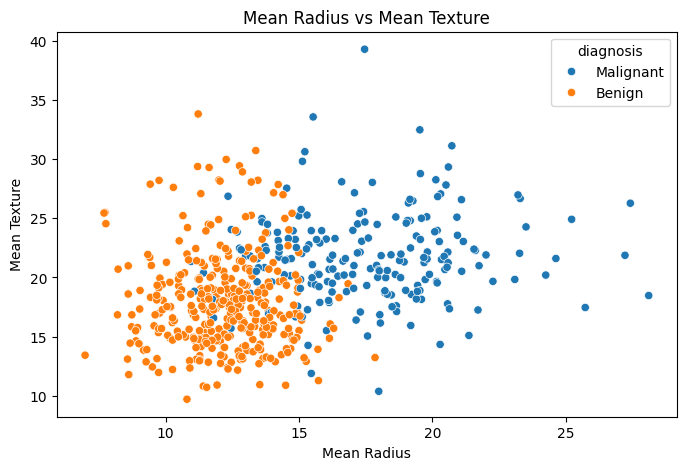

In [8]:
# Section 4.4: Compare radius and texture

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="mean radius",
    y="mean texture",
    hue="diagnosis"
)

plt.title("Mean Radius vs Mean Texture")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.show()


In [9]:
# Section 5: Prepare features and target

# X contains the 30 diagnostic features
X = df[cancer.feature_names]

# y contains the tumor diagnosis
# Change target values so 1 = Malignant and 0 = Benign
y = (df["target"] == 0).astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (569, 30)
Target shape: (569,)


In [10]:
# Section 6: Split the dataset

# Use 80% data for training and 20% for testing
# Stratify maintains similar class proportions

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 455
Testing records: 114


In [11]:
# Section 7: Create four classification models

# StandardScaler is used for Logistic Regression, KNN and SVM
# Pipelines help prevent data leakage during preprocessing

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf"))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

print("Four machine learning models created")


Four machine learning models created


In [12]:
# Section 8: Train all four models

for name, model in models.items():

    # Train each model using training data
    model.fit(X_train, y_train)

    print(name, "training completed")


Logistic Regression training completed
KNN training completed
SVM training completed
Random Forest training completed


In [13]:
# Section 9: Evaluate all models

# Create lists to store results and predictions
results = []
predictions = {}

for name, model in models.items():

    # Predict tumor diagnosis
    y_pred = model.predict(X_test)

    # Store predictions
    predictions[name] = y_pred

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # Calculate confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Save results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "False Negatives": fn,
        "False Positives": fp
    })

# Convert results into a table
results_df = pd.DataFrame(results)

print("Model Performance Results:")
print(results_df.round(4))


Model Performance Results:
                 Model  Accuracy  Precision  Recall  F1-Score  \
0  Logistic Regression    0.9649     0.9750  0.9286    0.9512   
1                  KNN    0.9561     0.9744  0.9048    0.9383   
2                  SVM    0.9737     1.0000  0.9286    0.9630   
3        Random Forest    0.9737     1.0000  0.9286    0.9630   

   False Negatives  False Positives  
0                3                1  
1                4                1  
2                3                0  
3                3                0  


In [14]:
# Section 9: Evaluate all models

import warnings

# Hide the joblib CPU detection warning on Windows
warnings.filterwarnings(
    "ignore",
    message="Could not find the number of physical cores.*",
    category=UserWarning
)

# Create lists to store results and predictions
results = []
predictions = {}

for name, model in models.items():

    # Predict tumor diagnosis
    y_pred = model.predict(X_test)

    # Store predictions
    predictions[name] = y_pred

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    # Calculate confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    # Save results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "False Negatives": fn,
        "False Positives": fp
    })

# Convert results into a table
results_df = pd.DataFrame(results)

# Display model performance results

# Display model performance results in a clean table
from IPython.display import display as show_table

print("Model Performance Results:")
show_table(results_df.round(4))


Model Performance Results:


,Model,Accuracy,Precision,Recall,F1-Score,False Negatives,False Positives
0,Logistic Regression,0.9649,0.9750,0.9286,0.9512,3,1
1,KNN,0.9561,0.9744,0.9048,0.9383,4,1
2,SVM,0.9737,1.0000,0.9286,0.9630,3,0
3,Random Forest,0.9737,1.0000,0.9286,0.9630,3,0


In [15]:
# Section 10: Display classification reports

for name, y_pred in predictions.items():

    print("\nModel:", name)

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Benign", "Malignant"]
    ))



Model: Logistic Regression
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114


Model: KNN
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


Model: SVM
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.9

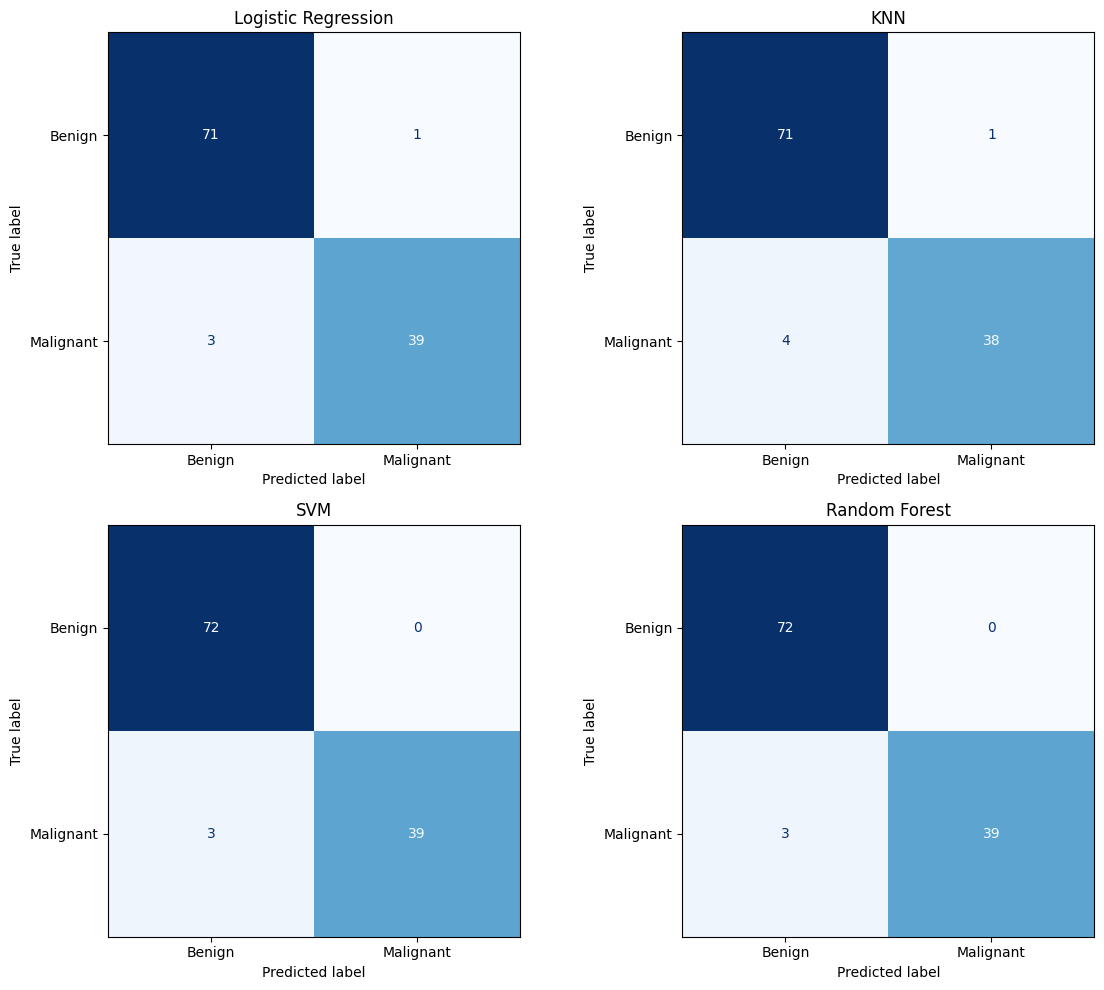

In [16]:
# Section 11: Display confusion matrices

# False negative means malignant predicted as benign
# False positive means benign predicted as malignant

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, y_pred) in zip(
    axes.flat, predictions.items()
):

    cm = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()


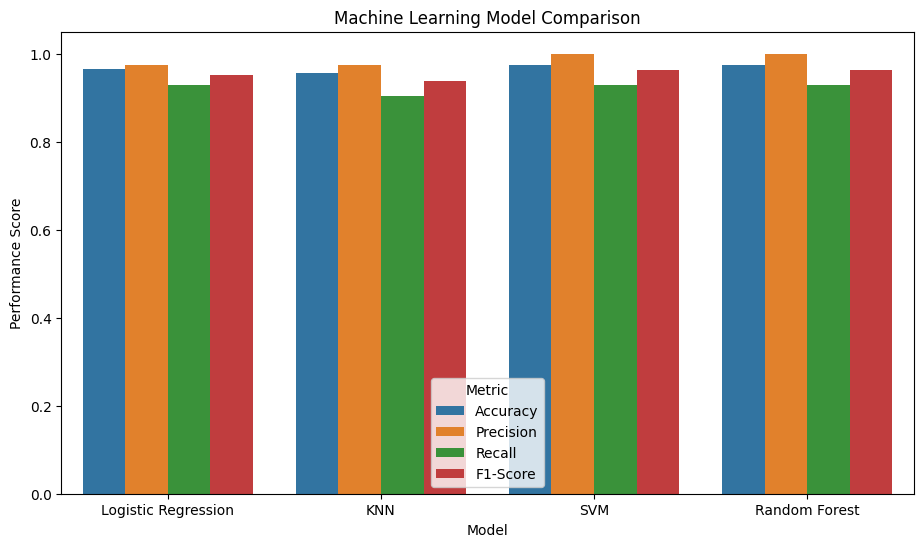

In [17]:
# Section 12: Compare model performance using a graph

# Select the evaluation metrics
comparison = results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Model")
plt.ylabel("Performance Score")
plt.ylim(0, 1.05)
plt.show()


In [18]:
# Section 13: Identify the best model

# Recall is important for identifying malignant tumors
# F1-score and accuracy are used to break ties

ranked_results = results_df.sort_values(
    by=["Recall", "F1-Score", "Accuracy"],
    ascending=False
)

best_model = ranked_results.iloc[0]

print("Best Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1-Score:", round(best_model["F1-Score"], 4))
print("False Negatives:", int(best_model["False Negatives"]))


Best Model: SVM
Accuracy: 0.9737
Precision: 1.0
Recall: 0.9286
F1-Score: 0.963
False Negatives: 3


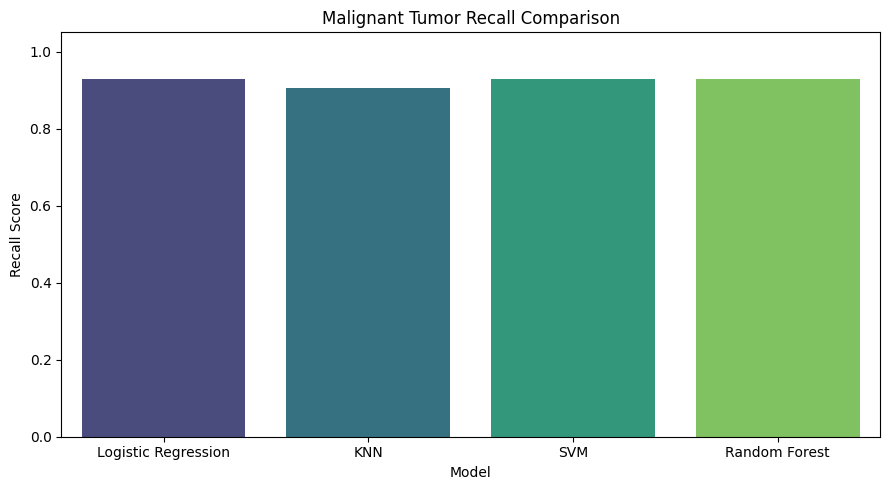

Project results saved successfully


In [19]:
# Section 14: Save the project results

# Save model performance table
results_df.to_csv(
    "breast_cancer_model_results.csv",
    index=False
)

# Create recall comparison graph
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Recall",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("Malignant Tumor Recall Comparison")
plt.xlabel("Model")
plt.ylabel("Recall Score")
plt.ylim(0, 1.05)
plt.tight_layout()

# Save graph as an image
plt.savefig(
    "breast_cancer_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Project results saved successfully")
